<a href="https://colab.research.google.com/github/duleab/-CrisisLens./blob/main/ecg_quality_noise_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lightweight ECG Signal-Quality Classification Under Controlled Ambulatory Noise

**Why.** Wearable and ambulatory ECG is routinely corrupted by baseline wander, electrode motion and muscle artifact. Downstream arrhythmia detection fails silently when these windows are not flagged, so a signal-quality gate that is small enough to run on a wearable is a practical prerequisite.

**Objective.** Classify 2-second ECG windows into three quality classes (clean, mild, severe) with a lightweight 1D-CNN, and compare it against handcrafted-feature baselines on accuracy, macro-F1, per-noise robustness and computational cost.

**Hypothesis.** A small 1D-CNN trained on windows with noise injected at known SNRs separates the three quality classes at least as well as logistic regression and random forest on handcrafted features, while keeping a parameter count, model size and CPU latency suitable for edge deployment. The notebook tests this; it does not assume it.

**Datasets.**
- MIT-BIH Arrhythmia Database (`mitdb`): 48 half-hour two-lead recordings at 360 Hz, used as the clean ECG source.
- MIT-BIH Noise Stress Test Database (`nstdb`): baseline wander (`bw`), electrode motion (`em`) and muscle artifact (`ma`) recordings at 360 Hz, used as the noise source.

**Protocol rules.**
- Train, validation and test partitions are patient-disjoint; records 201 and 202 belong to one patient and stay together.
- NSTDB noise is split by time into disjoint ranges per partition.
- Normalization statistics come from the training partition only.
- The test set is evaluated once per model family, after model selection is finished.

**Expected outputs.** Trained checkpoint, baseline models, split manifests, metrics, publication-ready figures and tables, efficiency measurements and a checksummed reproducibility package under `/kaggle/working/ecg_quality/`.

**Requirement.** Kaggle internet access must be enabled so that PhysioNet files can be downloaded.

## Stage 1: Environment and configuration

**Why.** Every later result depends on fixed seeds, one sampling rate and window length, and a single place where noise levels, split fractions and training settings are defined. Values scattered across cells are the main source of irreproducible experiments.

**How.** Cell 2 installs and imports libraries. Cell 3 defines all constants, seeding, device selection and the shared `evaluate()` used by every model.

In [1]:
# Cell 2: install and import
%pip install -q wfdb shap

import copy
import hashlib
import io
import json
import os
import pickle
import platform
import random
import shutil
import time
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.signal as sps
import shap
import torch
import torch.nn as nn
import wfdb
from IPython.display import display
from scipy.stats import kurtosis, skew
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             precision_recall_fscore_support)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset

warnings.filterwarnings("ignore")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.9/163.9 kB 1.4 MB/s eta 0:00:00


In [3]:
# Cell 3: global configuration
SEED = 42
FS = 360
WIN_SEC = 2
WIN = FS * WIN_SEC
MIN_STD = 1e-3

SPLITS = ["train", "val", "test"]
SPLIT_FRAC = {"train": 0.70, "val": 0.15, "test": 0.15}
NOISE_PART = {"train": (0.0, 0.6), "val": (0.6, 0.8), "test": (0.8, 1.0)}

CLASS_NAMES = ["clean", "mild", "severe"]
NOISE_NAMES = ["bw", "em", "ma"]
NOISE_LABEL = {"bw": "Baseline wander", "em": "Electrode motion", "ma": "Muscle artifact"}
SNR_LEVELS = {"mild": [18, 12], "severe": [6, 0]}
ALL_SNR = sorted([float(v) for lv in SNR_LEVELS.values() for v in lv], reverse=True)

TRAIN_CFG = dict(batch_size=256, epochs=40, lr=2e-3, weight_decay=1e-4, patience=8)

ON_KAGGLE = Path("/kaggle").exists()
ROOT = Path("/content/") if ON_KAGGLE else Path("working")
DATA_DIR = Path("/content/temp/physionet") if ON_KAGGLE else Path("data")
OUT_ROOT = ROOT / "ecg_quality"
OUT = {k: OUT_ROOT / k for k in ["models", "manifests", "metrics", "figures", "tables"]}
for p in [DATA_DIR, *OUT.values()]:
    p.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
TEST_LOG = []


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def evaluate(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], average="macro", zero_division=0)
    return {"accuracy": accuracy_score(y_true, y_pred), "macro_f1": f, "macro_precision": p,
            "macro_recall": r, "confusion_matrix": confusion_matrix(y_true, y_pred, labels=[0, 1, 2])}


def metrics_frame(results):
    cols = ["accuracy", "macro_f1", "macro_precision", "macro_recall"]
    return pd.DataFrame({k: {c: v[c] for c in cols} for k, v in results.items()}).T


set_seed()
print(f"device={DEVICE}, window={WIN} samples, outputs={OUT_ROOT}")

device=cpu, window=720 samples, outputs=/content/ecg_quality


## Stage 2: Dataset acquisition and inspection

**Why.** Silent data problems (wrong sampling rate, missing samples, unexpected channel order, shared patients) invalidate results without raising errors. They are cheap to detect before any modeling and expensive to discover after.

**How.** Cell 4 downloads the files once and skips existing ones. Cell 5 validates every recording and builds the record-to-patient map. Cell 6 plots representative signals to confirm that the noise recordings look as expected.

In [5]:
import zipfile
import os

zip_path = '/content/ECG_Signal_archive.zip'
extract_path = '/content/'

if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print(f"Successfully extracted {zip_path} to {extract_path}")
else:
    print(f"File not found: {zip_path}")

Successfully extracted /content/ECG_Signal_archive.zip to /content/


In [6]:
# Cell 4: Copy extracted MIT-BIH and NSTDB records locally
import shutil
from pathlib import Path

MITDB_DIR = DATA_DIR / "mitdb"
NSTDB_DIR = DATA_DIR / "nstdb"

# Source directories from the extracted zip
EXTRACTED_MITDB = Path("/content/mit-bih-arrhythmia-database-1.0.0")
EXTRACTED_NSTDB = Path("/content/physionet.org/files/nstdb/1.0.0")

def copy_records(src_dir, dest_dir, pattern="*.*"):
    dest_dir.mkdir(parents=True, exist_ok=True)
    copied = 0
    for file_path in src_dir.glob(pattern):
        if file_path.is_file():
            shutil.copy(file_path, dest_dir / file_path.name)
            copied += 1
    return copied

# Copy MITDB records
if EXTRACTED_MITDB.exists():
    copied_mit = copy_records(EXTRACTED_MITDB, MITDB_DIR)
    print(f"Copied {copied_mit} MITDB files locally.")
else:
    print(f"Extracted MITDB path not found at {EXTRACTED_MITDB}")

# Copy NSTDB records
if EXTRACTED_NSTDB.exists():
    copied_nst = copy_records(EXTRACTED_NSTDB, NSTDB_DIR)
    print(f"Copied {copied_nst} NSTDB files locally.")
else:
    print(f"Extracted NSTDB path not found at {EXTRACTED_NSTDB}")

MIT_RECORDS = sorted(p.stem for p in MITDB_DIR.glob("*.hea"))
print(f"{len(MIT_RECORDS)} MIT-BIH records locally configured.")

Copied 203 MITDB files locally.
Copied 64 NSTDB files locally.
48 MIT-BIH records locally configured.


In [7]:
# Cell 5: validate recordings
PATIENT = {r: r for r in MIT_RECORDS}
PATIENT["202"] = "201"


def pick_channel(names):
    return names.index("MLII") if "MLII" in names else 0


ecg_signals, rows = {}, []
for r in MIT_RECORDS:
    rec = wfdb.rdrecord(str(MITDB_DIR / r))
    ann = wfdb.rdann(str(MITDB_DIR / r), "atr")
    ch = pick_channel(rec.sig_name)
    sig = rec.p_signal[:, ch].astype(np.float32)
    ecg_signals[r] = sig
    rows.append(dict(record=r, patient=PATIENT[r], fs=rec.fs, channels=",".join(rec.sig_name),
                     used=rec.sig_name[ch], units=rec.units[ch], samples=rec.sig_len,
                     minutes=round(rec.sig_len / rec.fs / 60, 2), annotations=len(ann.sample),
                     nan_count=int(np.isnan(sig).sum()), std=float(np.nanstd(sig))))
mit_info = pd.DataFrame(rows)

noise_signals, rows = {}, []
for n in NOISE_NAMES:
    rec = wfdb.rdrecord(str(NSTDB_DIR / n))
    sig = rec.p_signal[:, 0].astype(np.float32)
    noise_signals[n] = sig
    rows.append(dict(noise=n, fs=rec.fs, channels=",".join(rec.sig_name), samples=rec.sig_len,
                     minutes=round(rec.sig_len / rec.fs / 60, 2), nan_count=int(np.isnan(sig).sum()),
                     std=float(np.nanstd(sig))))
noise_info = pd.DataFrame(rows)

assert (mit_info.fs == FS).all() and (noise_info.fs == FS).all()
assert mit_info.nan_count.sum() == 0 and noise_info.nan_count.sum() == 0
assert (mit_info["std"] > 0).all() and (noise_info["std"] > 0).all()
print(mit_info.used.value_counts().to_dict(), f"patients: {mit_info.patient.nunique()}")
display(mit_info.head())
display(noise_info)

{'MLII': 46, 'V5': 2} patients: 47


,record,patient,fs,channels,used,units,samples,minutes,annotations,nan_count,std
0,100,100,360,"MLII,V5",MLII,mV,650000,30.09,2274,0,0.193200
1,101,101,360,"MLII,V1",MLII,mV,650000,30.09,1874,0,0.261156
2,102,102,360,"V5,V2",V5,mV,650000,30.09,2192,0,0.190489
3,103,103,360,"MLII,V2",MLII,mV,650000,30.09,2091,0,0.321840
4,104,104,360,"V5,V2",V5,mV,650000,30.09,2311,0,0.250382


,noise,fs,channels,samples,minutes,nan_count,std
0,bw,360,"noise1,noise2",650000,30.09,0,0.465894
1,em,360,"noise1,noise2",650000,30.09,0,0.730151
2,ma,360,"noise1,noise2",650000,30.09,0,0.192669


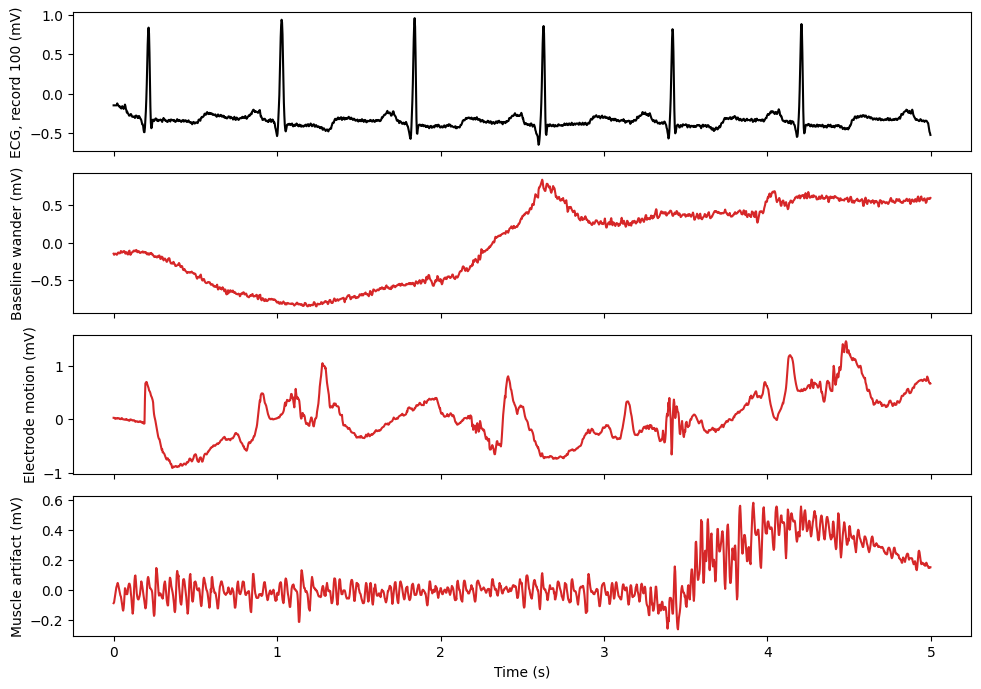

In [8]:
# Cell 6: visualize clean ECG and the three noise types
fig, axes = plt.subplots(4, 1, figsize=(10, 7), sharex=True)
t = np.arange(5 * FS) / FS
axes[0].plot(t, ecg_signals["100"][:5 * FS], color="k")
axes[0].set_ylabel("ECG, record 100 (mV)")
for ax, name in zip(axes[1:], NOISE_NAMES):
    ax.plot(t, noise_signals[name][:5 * FS], color="tab:red")
    ax.set_ylabel(f"{NOISE_LABEL[name]} (mV)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## Stage 3: Data preparation

**Why.** Reported accuracy is only meaningful if no information crosses partitions. Windows from the same patient are highly correlated, noise segments reused across partitions would be memorized, and normalization statistics computed on all data would leak test information. Each of these inflates results while looking harmless.

**How.** Cell 7 assigns whole patients to partitions. Cell 8 extracts windows and normalizes with training-only statistics. Cell 9 injects noise from time-disjoint NSTDB ranges at controlled SNRs and defines the quality labels. Cell 10 inspects class balance and builds the DataLoaders.

In [9]:
# Cell 7: patient-disjoint partitions
rng = np.random.default_rng(SEED)
patients = sorted(set(PATIENT.values()))
order = rng.permutation(len(patients))
n_tr = round(SPLIT_FRAC["train"] * len(patients))
n_va = round(SPLIT_FRAC["val"] * len(patients))

patient_split = {}
for rank, idx in enumerate(order):
    patient_split[patients[idx]] = "train" if rank < n_tr else "val" if rank < n_tr + n_va else "test"
SPLIT_RECORDS = {s: [r for r in MIT_RECORDS if patient_split[PATIENT[r]] == s] for s in SPLITS}

assert sum(len(v) for v in SPLIT_RECORDS.values()) == len(MIT_RECORDS)
assert any({"201", "202"} <= set(v) for v in SPLIT_RECORDS.values())
for s in SPLITS:
    print(s, len(SPLIT_RECORDS[s]), "records:", " ".join(SPLIT_RECORDS[s]))

train 34 records: 103 104 105 106 107 109 111 116 117 118 119 122 123 200 201 202 203 205 207 208 209 210 212 213 215 220 221 222 223 228 230 231 232 234
val 7 records: 100 112 113 115 121 124 217
test 7 records: 101 102 108 114 214 219 233


In [10]:
# Cell 8: window extraction and training-only normalization
ecg, meta = {}, {}
for s in SPLITS:
    chunks, rows, dropped = [], [], 0
    for r in SPLIT_RECORDS[s]:
        sig = ecg_signals[r]
        n = len(sig) // WIN
        w = sig[: n * WIN].reshape(n, WIN)
        ok = np.isfinite(w).all(axis=1) & (w.std(axis=1) > MIN_STD)
        dropped += int((~ok).sum())
        chunks.append(w[ok])
        rows += [(r, PATIENT[r], int(st)) for st in (np.arange(n) * WIN)[ok]]
    ecg[s] = np.concatenate(chunks).astype(np.float32)
    meta[s] = pd.DataFrame(rows, columns=["record", "patient", "win_start"])
    print(f"{s}: {len(ecg[s])} windows kept, {dropped} dropped")

NORM_MEAN = float(ecg["train"].mean())
NORM_STD = float(ecg["train"].std())
for s in SPLITS:
    ecg[s] = ((ecg[s] - NORM_MEAN) / NORM_STD).astype(np.float32)
print(f"train mean={NORM_MEAN:.4f}, std={NORM_STD:.4f}")

train: 30668 windows kept, 0 dropped
val: 6314 windows kept, 0 dropped
test: 6314 windows kept, 0 dropped
train mean=-0.3201, std=0.4738


In [11]:
# Cell 9: controlled noise injection and quality labels
NOISE_LEN = {n: len(noise_signals[n]) for n in NOISE_NAMES}
noise_bounds = {s: {n: (int(NOISE_PART[s][0] * NOISE_LEN[n]), int(NOISE_PART[s][1] * NOISE_LEN[n]))
                    for n in NOISE_NAMES} for s in SPLITS}


def inject(ecg_win, noise_win, snr_db):
    s = ecg_win - ecg_win.mean()
    n = noise_win - noise_win.mean()
    scale = np.sqrt(np.mean(s ** 2) / (np.mean(n ** 2) * 10 ** (snr_db / 10)))
    return ecg_win + scale * n


def make_split(s, seed):
    r = np.random.default_rng(seed)
    N = len(ecg[s])
    y = np.arange(N) % 3
    r.shuffle(y)
    ntype = r.integers(0, len(NOISE_NAMES), N)
    ntype[y == 0] = -1
    snr = np.full(N, np.nan)
    for k, name in ((1, "mild"), (2, "severe")):
        m = y == k
        snr[m] = r.choice(SNR_LEVELS[name], m.sum())
    nstart = np.full(N, -1, dtype=np.int64)
    x = ecg[s].copy()
    for i in np.flatnonzero(y > 0):
        name = NOISE_NAMES[ntype[i]]
        lo, hi = noise_bounds[s][name]
        nstart[i] = r.integers(lo, hi - WIN + 1)
        x[i] = inject(ecg[s][i], noise_signals[name][nstart[i]: nstart[i] + WIN], snr[i])
    return x, y, ntype, snr, nstart


X = {}
for s, off in zip(SPLITS, (1, 2, 3)):
    X[s], y, ntype, snr, nstart = make_split(s, SEED + off)
    meta[s]["label"] = y
    meta[s]["label_name"] = np.array(CLASS_NAMES)[y]
    meta[s]["noise_type"] = np.where(ntype >= 0, np.array(NOISE_NAMES)[ntype], "none")
    meta[s]["snr_db"] = snr
    meta[s]["noise_start"] = nstart
    assert np.isfinite(X[s]).all()
print({s: X[s].shape for s in SPLITS})

{'train': (30668, 720), 'val': (6314, 720), 'test': (6314, 720)}


,train,val,test
label_name,,,
clean,10223,2105,2105
mild,10223,2105,2105
severe,10222,2104,2104


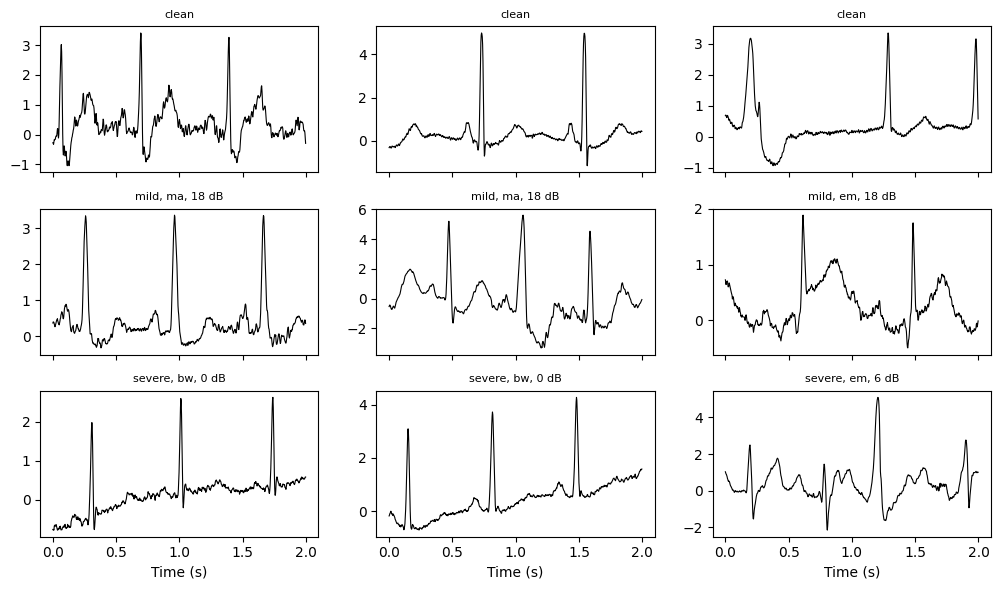

In [12]:
# Cell 10: class distribution, examples and DataLoaders
dist = pd.concat({s: meta[s].label_name.value_counts().reindex(CLASS_NAMES) for s in SPLITS}, axis=1)
display(dist)

t_win = np.arange(WIN) / FS
rs = np.random.default_rng(SEED)
fig, axes = plt.subplots(3, 3, figsize=(10, 6), sharex=True)
for k, cname in enumerate(CLASS_NAMES):
    idx = rs.choice(np.flatnonzero(meta["train"].label.values == k), 3, replace=False)
    for j, i in enumerate(idx):
        row = meta["train"].iloc[i]
        axes[k, j].plot(t_win, X["train"][i], color="k", lw=0.8)
        axes[k, j].set_title(f"{cname}, {row.noise_type}, {row.snr_db:.0f} dB" if k else cname, fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
plt.tight_layout()
plt.show()


class QualityDataset(Dataset):
    def __init__(self, x, y):
        self.x = torch.from_numpy(x).unsqueeze(1)
        self.y = torch.from_numpy(np.asarray(y, dtype=np.int64))

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


g = torch.Generator()
g.manual_seed(SEED)
loaders = {s: DataLoader(QualityDataset(X[s], meta[s].label.values), batch_size=TRAIN_CFG["batch_size"],
                         shuffle=(s == "train"), generator=g if s == "train" else None,
                         pin_memory=DEVICE.type == "cuda") for s in SPLITS}

## Stage 4: Baseline models

**Why.** A CNN result without a reference is uninterpretable. Quality classification may be solvable with a few signal statistics, in which case a deep model is unjustified. Baselines on interpretable features establish how much the CNN actually adds.

**How.** Cell 11 computes amplitude, difference and spectral features. Cell 12 fits logistic regression and random forest on the training partition and evaluates them on the validation partition only; the test partition stays sealed until Cell 19.

In [13]:
# Cell 11: handcrafted quality indicators
BANDS = [(0, 1), (1, 5), (5, 15), (15, 40), (40, 150)]
FEATURE_NAMES = (["std", "ptp", "rms_diff", "mean_abs_diff", "max_abs_diff", "zero_cross", "skew", "kurtosis"]
                 + [f"band_{lo}_{hi}" for lo, hi in BANDS] + ["spec_entropy", "spec_centroid"])


def extract_features(x):
    xc = x - x.mean(axis=1, keepdims=True)
    d = np.diff(x, axis=1)
    f, p = sps.welch(x, fs=FS, nperseg=WIN, detrend="constant", axis=1)
    pn = p / (p.sum(axis=1, keepdims=True) + 1e-12)
    band = [pn[:, (f >= lo) & (f < hi)].sum(axis=1) for lo, hi in BANDS]
    entropy = -(pn * np.log(pn + 1e-12)).sum(axis=1)
    centroid = (pn * f).sum(axis=1)
    zero_cross = (np.signbit(xc[:, 1:]) != np.signbit(xc[:, :-1])).mean(axis=1)
    feats = np.column_stack([x.std(axis=1), np.ptp(x, axis=1), np.sqrt((d ** 2).mean(axis=1)),
                             np.abs(d).mean(axis=1), np.abs(d).max(axis=1), zero_cross,
                             skew(x, axis=1), kurtosis(x, axis=1), *band, entropy, centroid])
    return feats.astype(np.float32)


FEAT = {s: extract_features(X[s]) for s in ("train", "val")}
print({s: FEAT[s].shape for s in FEAT}, np.isfinite(FEAT["train"]).all())

{'train': (30668, 15), 'val': (6314, 15)} True


In [14]:
# Cell 12: logistic regression and random forest baselines
baselines = {
    "logreg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=SEED)),
    "random_forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
}
y_train = meta["train"].label.values
y_val = meta["val"].label.values

baseline_val = {}
for name, mdl in baselines.items():
    mdl.fit(FEAT["train"], y_train)
    baseline_val[name] = evaluate(y_val, mdl.predict(FEAT["val"]))
display(metrics_frame(baseline_val).round(4))

,accuracy,macro_f1,macro_precision,macro_recall
logreg,0.5545,0.5161,0.5932,0.5545
random_forest,0.5657,0.5576,0.5605,0.5658


## Stage 5: Lightweight deep learning

**Why.** The deployment target is a wearable, so the architecture is deliberately small: three convolutional blocks, global average pooling and one linear layer. Global pooling removes the dependence on window length and keeps the parameter count low, and model selection on validation macro-F1 prevents the test set from influencing any choice.

**How.** Cell 13 defines the network and counts parameters. Cell 14 sets up loss, optimizer, scheduler and the shared epoch functions. Cell 15 trains with early stopping and saves the best checkpoint. Cell 16 evaluates that checkpoint once on the test partition.

In [15]:
# Cell 13: lightweight 1D-CNN
class QualityCNN(nn.Module):
    def __init__(self, n_classes=3):
        super().__init__()

        def block(cin, cout, k, pool):
            layers = [nn.Conv1d(cin, cout, k, padding=k // 2), nn.BatchNorm1d(cout), nn.ReLU()]
            return layers + ([nn.MaxPool1d(2)] if pool else [])

        self.features = nn.Sequential(*block(1, 16, 7, True), *block(16, 32, 5, True), *block(32, 64, 3, False))
        self.head = nn.Sequential(nn.AdaptiveAvgPool1d(1), nn.Flatten(), nn.Dropout(0.2), nn.Linear(64, n_classes))

    def forward(self, x):
        return self.head(self.features(x))


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)


print(f"trainable parameters: {count_params(QualityCNN()):,}")

trainable parameters: 9,347


In [16]:
# Cell 14: loss, optimizer, scheduler and epoch functions
set_seed()
model = QualityCNN().to(DEVICE)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=TRAIN_CFG["lr"], weight_decay=TRAIN_CFG["weight_decay"])
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)


def run_epoch(model, loader, train):
    model.train(train)
    total, n, ys, ps = 0.0, 0, [], []
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            out = model(xb)
            loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total += loss.item() * len(yb)
            n += len(yb)
            ys.append(yb.cpu().numpy())
            ps.append(out.argmax(1).cpu().numpy())
    return total / n, evaluate(np.concatenate(ys), np.concatenate(ps))


@torch.no_grad()
def predict(model, loader):
    model.eval()
    logits, ys = [], []
    for xb, yb in loader:
        logits.append(model(xb.to(DEVICE)).cpu())
        ys.append(yb)
    logits = torch.cat(logits)
    return torch.cat(ys).numpy(), logits.argmax(1).numpy(), torch.softmax(logits, 1).numpy()

In [17]:
# Cell 15: training with early stopping
CKPT_PATH = OUT["models"] / "best_cnn.pt"
history, best_f1, wait = [], -1.0, 0
for epoch in range(1, TRAIN_CFG["epochs"] + 1):
    tr_loss, tr_m = run_epoch(model, loaders["train"], True)
    va_loss, va_m = run_epoch(model, loaders["val"], False)
    scheduler.step(va_m["macro_f1"])
    history.append(dict(epoch=epoch, train_loss=tr_loss, val_loss=va_loss, train_acc=tr_m["accuracy"],
                        val_acc=va_m["accuracy"], train_macro_f1=tr_m["macro_f1"],
                        val_macro_f1=va_m["macro_f1"], lr=optimizer.param_groups[0]["lr"]))
    if va_m["macro_f1"] > best_f1:
        best_f1, wait = va_m["macro_f1"], 0
        torch.save({"state_dict": model.state_dict(), "epoch": epoch, "val_macro_f1": best_f1}, CKPT_PATH)
    else:
        wait += 1
    print(f"epoch {epoch:02d} train_loss {tr_loss:.4f} val_loss {va_loss:.4f} "
          f"val_acc {va_m['accuracy']:.4f} val_macro_f1 {va_m['macro_f1']:.4f}")
    if wait >= TRAIN_CFG["patience"]:
        print("early stopping")
        break
history = pd.DataFrame(history)
print(f"best validation macro-F1 {best_f1:.4f}")

epoch 01 train_loss 0.9315 val_loss 1.0551 val_acc 0.3891 val_macro_f1 0.2774
epoch 02 train_loss 0.8602 val_loss 0.9714 val_acc 0.4846 val_macro_f1 0.4796
epoch 03 train_loss 0.8321 val_loss 0.9055 val_acc 0.5253 val_macro_f1 0.4691
epoch 04 train_loss 0.8045 val_loss 0.8952 val_acc 0.5333 val_macro_f1 0.4823
epoch 05 train_loss 0.7946 val_loss 2.0186 val_acc 0.4213 val_macro_f1 0.3779
epoch 06 train_loss 0.7804 val_loss 1.0546 val_acc 0.4913 val_macro_f1 0.4358
epoch 07 train_loss 0.7780 val_loss 0.8017 val_acc 0.6036 val_macro_f1 0.5927
epoch 08 train_loss 0.7726 val_loss 1.0040 val_acc 0.5062 val_macro_f1 0.4523
epoch 09 train_loss 0.7568 val_loss 1.1841 val_acc 0.4764 val_macro_f1 0.4107
epoch 10 train_loss 0.7505 val_loss 1.0106 val_acc 0.5092 val_macro_f1 0.4566
epoch 11 train_loss 0.7500 val_loss 0.9283 val_acc 0.5225 val_macro_f1 0.5066
epoch 12 train_loss 0.7289 val_loss 0.7975 val_acc 0.5977 val_macro_f1 0.5675
epoch 13 train_loss 0.7191 val_loss 0.8095 val_acc 0.6058 val_ma

In [19]:
# Cell 16: single evaluation on the held-out test partition
ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
model.load_state_dict(ckpt["state_dict"])
TEST_LOG.append("cnn_test")
y_test, cnn_pred, cnn_prob = predict(model, loaders["test"])
cnn_test = evaluate(y_test, cnn_pred)
print(f"best epoch {ckpt['epoch']}")
print(classification_report(y_test, cnn_pred, target_names=CLASS_NAMES, digits=4))
print(cnn_test["confusion_matrix"])

best epoch 16
              precision    recall  f1-score   support

       clean     0.7451    0.2361    0.3586      2105
        mild     0.4171    0.5544    0.4760      2105
      severe     0.6402    0.8669    0.7365      2104

    accuracy                         0.5524      6314
   macro avg     0.6008    0.5525    0.5237      6314
weighted avg     0.6008    0.5524    0.5237      6314

[[ 497 1357  251]
 [ 164 1167  774]
 [   6  274 1824]]


## Stage 6: Robustness and efficiency

**Why.** An aggregate score can hide a model that handles one noise type well and fails on another, and "edge-ready" is a claim about cost, not accuracy. Per-noise and per-SNR breakdowns show where the classifier breaks, and measured cost lets the comparison with the baselines be fair.

**How.** Cell 17 breaks the stored CNN test predictions down by noise type and by predefined SNR level without re-running the test set. Cell 18 measures parameters, serialized size, MACs, activation size and single-thread CPU latency for all three models. Cell 19 evaluates the baselines on the test partition once and compiles the comparison.

In [20]:
# Cell 17: robustness by noise type and SNR
def noise_breakdown(m, y_pred):
    y = m.label.values
    rows = []
    for name in NOISE_NAMES:
        sel = (y == 0) | (m.noise_type.values == name)
        r = evaluate(y[sel], y_pred[sel])
        rows.append(dict(noise=name, n=int(sel.sum()), accuracy=r["accuracy"], macro_f1=r["macro_f1"]))
    return pd.DataFrame(rows)


def snr_breakdown(m, y_pred):
    y = m.label.values
    ok = y > 0
    df = pd.DataFrame({"noise": m.noise_type.values[ok], "snr_db": m.snr_db.values[ok],
                       "correct": (y_pred[ok] == y[ok]).astype(float)})
    return df.pivot_table(index="noise", columns="snr_db", values="correct", aggfunc="mean").reindex(
        index=NOISE_NAMES, columns=ALL_SNR)


robust_type = noise_breakdown(meta["test"], cnn_pred)
robust_snr = snr_breakdown(meta["test"], cnn_pred)
display(robust_type.round(4))
display(robust_snr.round(4))

,noise,n,accuracy,macro_f1
0,bw,3519,0.4132,0.4362
1,em,3438,0.4284,0.4583
2,ma,3567,0.4359,0.4551


snr_db,18.0,12.0,6.0,0.0
noise,,,,
bw,0.5762,0.4758,0.7262,0.9224
em,0.6381,0.5697,0.7151,0.9829
ma,0.6630,0.4194,0.8510,0.9890


In [21]:
# Cell 18: parameters, size, MACs, activation size and CPU latency
def count_complexity(m):
    macs, acts, hooks = [0], [], []

    def conv_h(mod, i, o):
        macs[0] += o.numel() * (mod.in_channels // mod.groups) * mod.kernel_size[0]

    def lin_h(mod, i, o):
        macs[0] += mod.in_features * mod.out_features * (o.numel() // mod.out_features)

    def act_h(mod, i, o):
        acts.append(o.numel() * 4)

    for mod in m.modules():
        if isinstance(mod, nn.Conv1d):
            hooks.append(mod.register_forward_hook(conv_h))
        elif isinstance(mod, nn.Linear):
            hooks.append(mod.register_forward_hook(lin_h))
        if not list(mod.children()):
            hooks.append(mod.register_forward_hook(act_h))
    m.eval()
    with torch.no_grad():
        m(torch.zeros(1, 1, WIN))
    for h in hooks:
        h.remove()
    return macs[0], max(acts) / 1e6


def time_fn(fn, warmup, runs):
    for _ in range(warmup):
        fn()
    t = []
    for _ in range(runs):
        s0 = time.perf_counter()
        fn()
        t.append((time.perf_counter() - s0) * 1000)
    return float(np.median(t)), float(np.percentile(t, 95))


prev_threads = torch.get_num_threads()
torch.set_num_threads(1)
x_probe = X["val"][:1]

cpu_model = copy.deepcopy(model).cpu().eval()
x_probe_t = torch.from_numpy(x_probe).unsqueeze(1)


def cnn_infer():
    with torch.inference_mode():
        cpu_model(x_probe_t)


buf = io.BytesIO()
torch.save(cpu_model.state_dict(), buf)
macs, peak_act_mb = count_complexity(copy.deepcopy(cpu_model))
lat = time_fn(cnn_infer, 50, 500)
eff = {"cnn": dict(parameters=count_params(cpu_model), size_mb=buf.getbuffer().nbytes / 1e6, macs_m=macs / 1e6,
                   flops_m=2 * macs / 1e6, peak_activation_mb=peak_act_mb,
                   cpu_latency_ms_median=lat[0], cpu_latency_ms_p95=lat[1])}

for name, mdl in baselines.items():
    est = copy.deepcopy(mdl)
    if name == "random_forest":
        est.set_params(n_jobs=1)
        n_params = sum(t.tree_.node_count for t in est.estimators_)
    else:
        lr = est[-1]
        n_params = lr.coef_.size + lr.intercept_.size
    lat = time_fn(lambda: est.predict(extract_features(x_probe)), 20, 200)
    eff[name] = dict(parameters=n_params, size_mb=len(pickle.dumps(est)) / 1e6, macs_m=np.nan, flops_m=np.nan,
                     peak_activation_mb=np.nan, cpu_latency_ms_median=lat[0], cpu_latency_ms_p95=lat[1])
torch.set_num_threads(prev_threads)

efficiency_df = pd.DataFrame(eff).T
efficiency_df["parameters"] = efficiency_df["parameters"].astype(int)
print(f"single-thread CPU, batch 1: {platform.processor() or platform.machine()}, {os.cpu_count()} logical cores")
print("baseline latency includes feature extraction; random forest parameters are total tree nodes")
display(efficiency_df.round(4))

single-thread CPU, batch 1: x86_64, 2 logical cores
baseline latency includes feature extraction; random forest parameters are total tree nodes


,parameters,size_mb,macs_m,flops_m,peak_activation_mb,cpu_latency_ms_median,cpu_latency_ms_p95
cnn,9347,0.0457,2.1084,4.2167,0.0461,0.4213,0.5374
logreg,48,0.0019,NaN,NaN,NaN,3.3750,4.2936
random_forest,1788278,157.4364,NaN,NaN,NaN,21.5155,27.6685


In [22]:
# Cell 19: baseline test evaluation and fair comparison
TEST_LOG.append("baseline_test")
FEAT["test"] = extract_features(X["test"])
MODEL_LABEL = {"cnn": "1D-CNN", "logreg": "Logistic regression", "random_forest": "Random forest"}

test_preds = {"cnn": cnn_pred}
test_metrics = {"cnn": cnn_test}
for name, mdl in baselines.items():
    test_preds[name] = mdl.predict(FEAT["test"])
    test_metrics[name] = evaluate(y_test, test_preds[name])

comparison = metrics_frame(test_metrics).join(
    efficiency_df[["parameters", "size_mb", "macs_m", "cpu_latency_ms_median"]])
per_noise = pd.concat({k: noise_breakdown(meta["test"], v).set_index("noise")[["accuracy", "macro_f1"]]
                       for k, v in test_preds.items()}, axis=1)
display(comparison.round(4))
display(per_noise.round(4))

,accuracy,macro_f1,macro_precision,macro_recall,parameters,size_mb,macs_m,cpu_latency_ms_median
cnn,0.5524,0.5237,0.6008,0.5525,9347,0.0457,2.1084,0.4213
logreg,0.5953,0.5923,0.6047,0.5954,48,0.0019,NaN,3.3750
random_forest,0.5855,0.5833,0.5822,0.5856,1788278,157.4364,NaN,21.5155


cnn            logreg          random_forest         
      accuracy macro_f1 accuracy macro_f1      accuracy macro_f1
noise                                                           
bw      0.4132   0.4362   0.6567   0.6119        0.5644   0.5551
em      0.4284   0.4583   0.5675   0.4736        0.5137   0.4907
ma      0.4359   0.4551   0.7040   0.6701        0.5957   0.5902

## Stage 7: Paper figures and analysis

**Why.** Figures and tables generated by code from the stored results cannot drift from the numbers in the paper, and an explicit summary of limitations prevents claims that the experiments do not support.

**How.** Cell 20 writes vector and raster figures at journal sizes, including a SHAP summary for the random-forest baseline on validation data. Cell 21 writes CSV and LaTeX tables. Cell 22 generates a findings summary directly from the computed metrics.

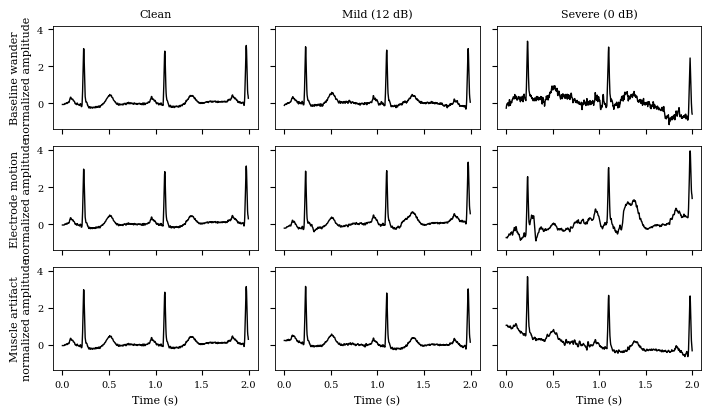

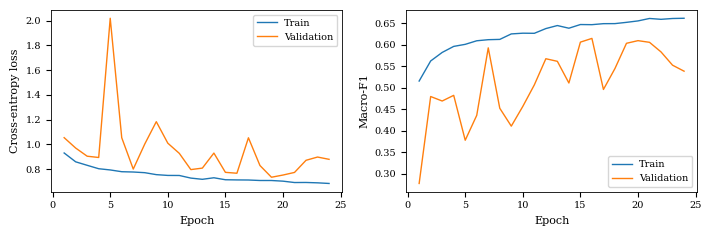

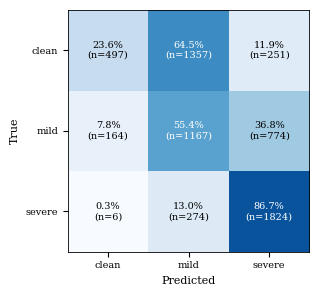

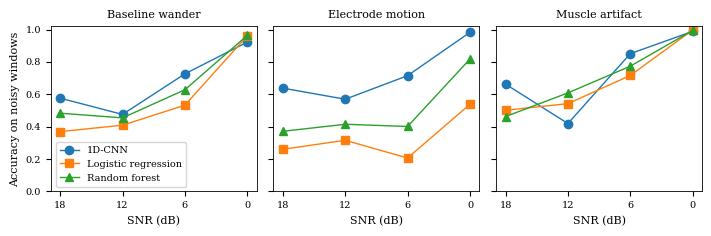

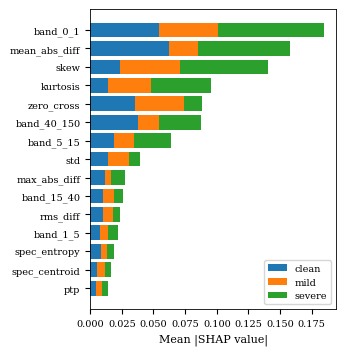

In [23]:
# Cell 20: publication-ready figures
plt.rcParams.update({"font.family": "serif", "font.size": 8, "axes.labelsize": 8, "axes.titlesize": 8,
                     "legend.fontsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7, "axes.linewidth": 0.6,
                     "lines.linewidth": 1.0, "savefig.dpi": 300, "savefig.bbox": "tight"})


def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(OUT["figures"] / f"{name}.{ext}")
    plt.show()


ref = ecg["test"][0]
mild_snr, severe_snr = min(SNR_LEVELS["mild"]), min(SNR_LEVELS["severe"])
fig, axes = plt.subplots(3, 3, figsize=(7.16, 4.2), sharex=True, sharey=True)
for i, name in enumerate(NOISE_NAMES):
    lo = noise_bounds["test"][name][0] + 1000
    seg = noise_signals[name][lo: lo + WIN]
    for j, (title, snr) in enumerate([("Clean", None), (f"Mild ({mild_snr} dB)", mild_snr),
                                      (f"Severe ({severe_snr} dB)", severe_snr)]):
        axes[i, j].plot(t_win, ref if snr is None else inject(ref, seg, snr), color="k")
        if i == 0:
            axes[i, j].set_title(title)
        if j == 0:
            axes[i, j].set_ylabel(f"{NOISE_LABEL[name]}\nnormalized amplitude")
for ax in axes[-1]:
    ax.set_xlabel("Time (s)")
fig.tight_layout()
save_fig(fig, "fig1_waveforms")

fig, axes = plt.subplots(1, 2, figsize=(7.16, 2.4))
axes[0].plot(history.epoch, history.train_loss, label="Train")
axes[0].plot(history.epoch, history.val_loss, label="Validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[1].plot(history.epoch, history.train_macro_f1, label="Train")
axes[1].plot(history.epoch, history.val_macro_f1, label="Validation")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Macro-F1")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "fig2_learning_curves")

cm = cnn_test["confusion_matrix"]
cmn = cm / cm.sum(axis=1, keepdims=True)
fig, ax = plt.subplots(figsize=(3.5, 3.0))
ax.imshow(cmn, vmin=0, vmax=1, cmap="Blues")
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cmn[i, j] * 100:.1f}%\n(n={cm[i, j]})", ha="center", va="center",
                color="white" if cmn[i, j] > 0.5 else "black", fontsize=7)
ax.set_xticks(range(3))
ax.set_yticks(range(3))
ax.set_xticklabels(CLASS_NAMES)
ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
fig.tight_layout()
save_fig(fig, "fig3_confusion_matrix")

markers = {"cnn": "o", "logreg": "s", "random_forest": "^"}
fig, axes = plt.subplots(1, 3, figsize=(7.16, 2.4), sharey=True)
for ax, name in zip(axes, NOISE_NAMES):
    for key, pred in test_preds.items():
        row = snr_breakdown(meta["test"], pred).loc[name]
        ax.plot(range(len(row)), row.values, marker=markers[key], label=MODEL_LABEL[key])
    ax.set_xticks(range(len(ALL_SNR)))
    ax.set_xticklabels([f"{v:.0f}" for v in ALL_SNR])
    ax.set_title(NOISE_LABEL[name])
    ax.set_xlabel("SNR (dB)")
    ax.set_ylim(0, 1.02)
axes[0].set_ylabel("Accuracy on noisy windows")
axes[0].legend()
fig.tight_layout()
save_fig(fig, "fig4_noise_robustness")

explainer = shap.TreeExplainer(baselines["random_forest"])
sv = explainer.shap_values(FEAT["val"][:500], check_additivity=False)
sv = np.stack(sv) if isinstance(sv, list) else np.moveaxis(sv, -1, 0)
imp = np.abs(sv).mean(axis=1)
rank = imp.sum(axis=0).argsort()
fig, ax = plt.subplots(figsize=(3.5, 3.6))
left = np.zeros(len(rank))
for k, cname in enumerate(CLASS_NAMES):
    ax.barh(np.arange(len(rank)), imp[k][rank], left=left, label=cname)
    left += imp[k][rank]
ax.set_yticks(np.arange(len(rank)))
ax.set_yticklabels([FEATURE_NAMES[i] for i in rank])
ax.set_xlabel("Mean |SHAP value|")
ax.legend()
fig.tight_layout()
save_fig(fig, "fig5_shap_random_forest")

In [24]:
# Cell 21: IEEE-ready tables
def save_table(df, name, caption, label):
    df.to_csv(OUT["tables"] / f"{name}.csv", index=False)
    tex = df.to_latex(index=False, float_format="%.3f", caption=caption, label=label, escape=True)
    (OUT["tables"] / f"{name}.tex").write_text(tex)
    display(df)


t_part = pd.DataFrame([dict(Partition=s, Patients=meta[s].patient.nunique(), Records=meta[s].record.nunique(),
                            Windows=len(meta[s])) for s in SPLITS])
t_class = pd.DataFrame([dict(Partition=s, **meta[s].label_name.value_counts().reindex(CLASS_NAMES).to_dict(),
                             Total=len(meta[s])) for s in SPLITS])
t_comp = comparison.reset_index().rename(columns={
    "index": "Model", "accuracy": "Accuracy", "macro_f1": "Macro-F1", "macro_precision": "Macro precision",
    "macro_recall": "Macro recall", "parameters": "Parameters", "size_mb": "Size (MB)", "macs_m": "MACs (M)",
    "cpu_latency_ms_median": "CPU latency (ms)"})
t_comp["Model"] = t_comp["Model"].map(MODEL_LABEL)
t_eff = efficiency_df.reset_index().rename(columns={
    "index": "Model", "parameters": "Parameters", "size_mb": "Size (MB)", "macs_m": "MACs (M)",
    "flops_m": "FLOPs (M)", "peak_activation_mb": "Peak activation (MB)",
    "cpu_latency_ms_median": "Latency median (ms)", "cpu_latency_ms_p95": "Latency p95 (ms)"})
t_eff["Model"] = t_eff["Model"].map(MODEL_LABEL)

save_table(t_part, "table1_partitions", "Dataset partitions (patient-disjoint).", "tab:partitions")
save_table(t_class, "table2_class_distribution", "Class distribution per partition (windows).", "tab:classes")
save_table(t_comp, "table3_model_comparison", "Test-set comparison of the CNN and baselines.", "tab:comparison")
save_table(t_eff, "table4_efficiency", "Computational cost (single-thread CPU, batch size 1).", "tab:efficiency")

,Partition,Patients,Records,Windows
0,train,33,34,30668
1,val,7,7,6314
2,test,7,7,6314


,Partition,clean,mild,severe,Total
0,train,10223,10223,10222,30668
1,val,2105,2105,2104,6314
2,test,2105,2105,2104,6314


,Model,Accuracy,Macro-F1,Macro precision,Macro recall,Parameters,Size (MB),MACs (M),CPU latency (ms)
0,1D-CNN,0.552423,0.523715,0.600812,0.552473,9347,0.045662,2.108352,0.421264
1,Logistic regression,0.595344,0.592279,0.604697,0.595355,48,0.001854,NaN,3.374997
2,Random forest,0.585524,0.583349,0.582210,0.585553,1788278,157.436419,NaN,21.515532


,Model,Parameters,Size (MB),MACs (M),FLOPs (M),Peak activation (MB),Latency median (ms),Latency p95 (ms)
0,1D-CNN,9347,0.045662,2.108352,4.216704,0.04608,0.421264,0.537413
1,Logistic regression,48,0.001854,NaN,NaN,NaN,3.374997,4.293634
2,Random forest,1788278,157.436419,NaN,NaN,NaN,21.515532,27.668537


In [25]:
# Cell 22: findings summary generated from computed metrics
best = comparison["macro_f1"].idxmax()
cnn_snr = snr_breakdown(meta["test"], cnn_pred)
worst_noise, worst_snr = cnn_snr.stack().idxmin()
lines = [f"Highest test macro-F1: {MODEL_LABEL[best]} ({comparison.loc[best, 'macro_f1']:.4f})."]
for k in comparison.index:
    r = comparison.loc[k]
    lines.append(f"{MODEL_LABEL[k]}: accuracy {r.accuracy:.4f}, macro-F1 {r.macro_f1:.4f}, "
                 f"{int(r.parameters):,} parameters, {r.size_mb:.4f} MB, "
                 f"{r.cpu_latency_ms_median:.3f} ms median CPU latency.")
lines.append(f"Lowest CNN accuracy over noise type and SNR: {NOISE_LABEL[worst_noise]} at {worst_snr:.0f} dB "
             f"({cnn_snr.loc[worst_noise, worst_snr]:.4f}).")
lines += [
    "Limitations:",
    "- Noise is synthetic: NSTDB recordings are added to MIT-BIH ECG at set SNRs, not recorded on a wearable.",
    "- The clean class is not noise-free; MIT-BIH recordings contain intrinsic artifacts.",
    "- Quality classes are defined by injected SNR ranges, not by clinician annotation.",
    "- Results come from one partition draw and one training seed; no variance estimate is reported.",
    "- Latency is measured on the notebook CPU, not on a wearable or edge device.",
    "- MIT-BIH has 47 patients, so partitions are small at the patient level.",
]
summary = "\n".join(lines)
(OUT["metrics"] / "findings.txt").write_text(summary)
print(summary)

Highest test macro-F1: Logistic regression (0.5923).
1D-CNN: accuracy 0.5524, macro-F1 0.5237, 9,347 parameters, 0.0457 MB, 0.421 ms median CPU latency.
Logistic regression: accuracy 0.5953, macro-F1 0.5923, 48 parameters, 0.0019 MB, 3.375 ms median CPU latency.
Random forest: accuracy 0.5855, macro-F1 0.5833, 1,788,278 parameters, 157.4364 MB, 21.516 ms median CPU latency.
Lowest CNN accuracy over noise type and SNR: Muscle artifact at 12 dB (0.4194).
Limitations:
- Noise is synthetic: NSTDB recordings are added to MIT-BIH ECG at set SNRs, not recorded on a wearable.
- The clean class is not noise-free; MIT-BIH recordings contain intrinsic artifacts.
- Quality classes are defined by injected SNR ranges, not by clinician annotation.
- Results come from one partition draw and one training seed; no variance estimate is reported.
- Latency is measured on the notebook CPU, not on a wearable or edge device.
- MIT-BIH has 47 patients, so partitions are small at the patient level.


## Stage 8: Export and reproducibility

**Why.** A result that cannot be regenerated or independently checked is not a result. Saving the preprocessing parameters, split manifests and checksums together with the model lets a reviewer verify exactly which windows, noise segments and statistics produced each number.

**How.** Cell 23 writes the model, configurations, manifests, metrics and figures to `/kaggle/working/`. Cell 24 runs consistency checks (leakage, sealed test use, checkpoint reload), checksums every file and builds a single archive.

In [26]:
# Cell 23: export model, configuration, manifests and metrics
def jdump(obj, path):
    def default(o):
        if isinstance(o, np.ndarray):
            return o.tolist()
        if isinstance(o, np.integer):
            return int(o)
        if isinstance(o, np.floating):
            return float(o)
        return str(o)
    Path(path).write_text(json.dumps(obj, indent=2, default=default))


for s in SPLITS:
    meta[s].to_csv(OUT["manifests"] / f"{s}_manifest.csv", index=False)
joblib.dump(baselines, OUT["models"] / "baselines.joblib")
history.to_csv(OUT["metrics"] / "training_history.csv", index=False)
comparison.to_csv(OUT["metrics"] / "model_comparison.csv")
per_noise.to_csv(OUT["metrics"] / "per_noise_comparison.csv")
efficiency_df.to_csv(OUT["metrics"] / "efficiency.csv")

jdump(dict(fs=FS, window_samples=WIN, norm_mean=NORM_MEAN, norm_std=NORM_STD, min_window_std=MIN_STD,
           snr_levels=SNR_LEVELS, noise_partition=NOISE_PART, noise_lengths=NOISE_LEN,
           channel_per_record=dict(zip(mit_info.record, mit_info.used)), patient_split=patient_split,
           split_records=SPLIT_RECORDS, feature_names=FEATURE_NAMES, bands=BANDS),
      OUT["metrics"] / "preprocessing_config.json")
jdump(dict(seed=SEED, train_cfg=TRAIN_CFG, split_fraction=SPLIT_FRAC, classes=CLASS_NAMES, noise_types=NOISE_NAMES,
           versions=dict(python=platform.python_version(), torch=torch.__version__, numpy=np.__version__,
                         sklearn=__import__("sklearn").__version__, wfdb=wfdb.__version__),
           device=str(DEVICE)),
      OUT["metrics"] / "experiment_config.json")
jdump(dict(best_epoch=int(ckpt["epoch"]), validation_baselines=baseline_val, test=test_metrics,
           robustness_by_noise=robust_type.to_dict("records"),
           robustness_by_snr=robust_snr.rename(columns=str).to_dict()),
      OUT["metrics"] / "metrics.json")
print(sorted(str(p.relative_to(OUT_ROOT)) for p in OUT_ROOT.rglob("*") if p.is_file()))

['figures/fig1_waveforms.pdf', 'figures/fig1_waveforms.png', 'figures/fig2_learning_curves.pdf', 'figures/fig2_learning_curves.png', 'figures/fig3_confusion_matrix.pdf', 'figures/fig3_confusion_matrix.png', 'figures/fig4_noise_robustness.pdf', 'figures/fig4_noise_robustness.png', 'figures/fig5_shap_random_forest.pdf', 'figures/fig5_shap_random_forest.png', 'manifests/test_manifest.csv', 'manifests/train_manifest.csv', 'manifests/val_manifest.csv', 'metrics/efficiency.csv', 'metrics/experiment_config.json', 'metrics/findings.txt', 'metrics/metrics.json', 'metrics/model_comparison.csv', 'metrics/per_noise_comparison.csv', 'metrics/preprocessing_config.json', 'metrics/training_history.csv', 'models/baselines.joblib', 'models/best_cnn.pt', 'tables/table1_partitions.csv', 'tables/table1_partitions.tex', 'tables/table2_class_distribution.csv', 'tables/table2_class_distribution.tex', 'tables/table3_model_comparison.csv', 'tables/table3_model_comparison.tex', 'tables/table4_efficiency.csv', 't

In [27]:
# Cell 24: consistency checks and packaging
sets = {s: set(meta[s].patient) for s in SPLITS}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
assert any({"201", "202"} <= set(v) for v in SPLIT_RECORDS.values())

for n in NOISE_NAMES:
    assert noise_bounds["train"][n][1] <= noise_bounds["val"][n][0] and noise_bounds["val"][n][1] <= noise_bounds["test"][n][0]
for s in SPLITS:
    noisy = meta[s][meta[s].label > 0]
    for n in NOISE_NAMES:
        sub = noisy[noisy.noise_type == n]
        lo, hi = noise_bounds[s][n]
        assert (sub.noise_start >= lo).all() and (sub.noise_start + WIN <= hi).all()
    counts = meta[s].label.value_counts()
    assert counts.max() - counts.min() <= 1
    assert np.isfinite(X[s]).all()

assert TEST_LOG == ["cnn_test", "baseline_test"], TEST_LOG

reloaded = QualityCNN().to(DEVICE)
reloaded.load_state_dict(torch.load(CKPT_PATH, map_location=DEVICE)["state_dict"])
reloaded.eval()
model.eval()
xb = torch.from_numpy(X["val"][:256]).unsqueeze(1).to(DEVICE)
with torch.no_grad():
    assert torch.allclose(model(xb), reloaded(xb), atol=1e-6)


def sha256(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()


files = sorted(p for p in OUT_ROOT.rglob("*") if p.is_file() and p.name != "checksums.json")
(OUT_ROOT / "checksums.json").write_text(json.dumps({str(p.relative_to(OUT_ROOT)): sha256(p) for p in files}, indent=2))
archive = shutil.make_archive(str(ROOT / "ecg_quality_package"), "zip", OUT_ROOT)
print(f"all checks passed, {len(files)} files, archive: {archive}")

all checks passed, 31 files, archive: /content/ecg_quality_package.zip
